## Random Forest

On reprend les données Boston du précédent TP.

> Ajuster sur les données Boston une forêt aléatoire composée de 10 arbres avec un nombre maximal de 4 variables considérées à chaque noeud (consulter la [doc](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor)).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]
raw_df

X_Bost = data
Y_Bost = target
print(np.shape(X_Bost))

(506, 13)


In [ ]:
#Ajustement de la Random Forest sur les données
from sklearn.ensemble import RandomForestRegressor

RF = RandomForestRegressor(n_estimators=10, max_features=4)
RF.fit(X_Bost, Y_Bost)

RandomForestRegressor(max_features=4, n_estimators=10)

> L'attribut `.estimators_` contient la structure des 10 arbres de la forêt. Calculer les prédictions sur les mêmes données à partir de ces 10 arbres. Comparer avec la prédiction directement fournie  par la méthode `predict` de `RandomForestRegressor`.

In [ ]:
Predict_list = [RF.estimators_[i].predict(X_Bost) for i in range(10)]

In [ ]:
pred_moyen=np.mean(Predict_list,axis=0)
pred_moyen

array([23.81, 22.33, 33.3 , 32.49, 34.59, 27.57, 21.95, 26.26, 16.  ,
       19.29, 19.37, 19.87, 20.73, 19.88, 18.24, 19.71, 22.39, 17.43,
       19.59, 18.58, 14.42, 19.3 , 15.01, 14.62, 16.17, 14.95, 16.58,
       15.36, 18.44, 20.77, 13.1 , 18.73, 14.19, 13.19, 13.86, 19.7 ,
       20.07, 20.74, 21.98, 30.96, 35.2 , 26.3 , 24.06, 24.45, 21.47,
       19.72, 20.21, 17.86, 16.37, 19.03, 20.07, 20.88, 25.91, 22.37,
       20.64, 34.73, 24.52, 31.71, 23.64, 19.75, 19.74, 17.03, 22.6 ,
       23.94, 33.  , 24.81, 19.77, 21.93, 18.27, 21.03, 23.68, 22.28,
       22.96, 24.12, 23.59, 21.69, 20.34, 20.64, 21.4 , 20.64, 26.94,
       23.79, 24.72, 22.95, 23.59, 26.27, 20.74, 21.87, 23.91, 28.96,
       23.72, 22.31, 23.19, 25.19, 21.13, 26.28, 22.72, 41.07, 44.78,
       32.88, 27.34, 26.25, 19.27, 19.34, 19.98, 19.5 , 19.43, 20.34,
       19.79, 20.05, 21.59, 22.78, 19.51, 19.2 , 19.66, 18.6 , 20.63,
       19.64, 19.56, 19.62, 21.45, 20.67, 19.35, 18.15, 18.69, 21.01,
       16.83, 16.33,

In [ ]:
RF.predict(X_Bost)

array([23.81, 22.33, 33.3 , 32.49, 34.59, 27.57, 21.95, 26.26, 16.  ,
       19.29, 19.37, 19.87, 20.73, 19.88, 18.24, 19.71, 22.39, 17.43,
       19.59, 18.58, 14.42, 19.3 , 15.01, 14.62, 16.17, 14.95, 16.58,
       15.36, 18.44, 20.77, 13.1 , 18.73, 14.19, 13.19, 13.86, 19.7 ,
       20.07, 20.74, 21.98, 30.96, 35.2 , 26.3 , 24.06, 24.45, 21.47,
       19.72, 20.21, 17.86, 16.37, 19.03, 20.07, 20.88, 25.91, 22.37,
       20.64, 34.73, 24.52, 31.71, 23.64, 19.75, 19.74, 17.03, 22.6 ,
       23.94, 33.  , 24.81, 19.77, 21.93, 18.27, 21.03, 23.68, 22.28,
       22.96, 24.12, 23.59, 21.69, 20.34, 20.64, 21.4 , 20.64, 26.94,
       23.79, 24.72, 22.95, 23.59, 26.27, 20.74, 21.87, 23.91, 28.96,
       23.72, 22.31, 23.19, 25.19, 21.13, 26.28, 22.72, 41.07, 44.78,
       32.88, 27.34, 26.25, 19.27, 19.34, 19.98, 19.5 , 19.43, 20.34,
       19.79, 20.05, 21.59, 22.78, 19.51, 19.2 , 19.66, 18.6 , 20.63,
       19.64, 19.56, 19.62, 21.45, 20.67, 19.35, 18.15, 18.69, 21.01,
       16.83, 16.33,

In [ ]:
RF.predict(X_Bost) == pred_moyen

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [ ]:
Les deux méthodes fournissent la même prédiction

Les deux méthodes fournissent la même prédiction


Les performances de prévision sont évaluées par défaut dans sckit-learn via le score $R^2$ (voir le précédent TP). La démarche standard est de calculer ce score par validation croisée sur des échantillons tests obtenus par K-fold (score test). Pour les Bagged Tree et les Random Forest, il est possible de se passer de validation croisée en calculant ce score par la méthode out-of-bag (score OOB).

> On souhaite comparer les scores OOB et les scores de test (via une validation croisée K-fold) pour des RF avec un nombre d'arbres entre 5 et 100 (`n_estimators=`). On demande le calcul du score OOB dans la forêt aléatoire avec l'argument `oob_score = True`. Pour  évaluer le score sur un échantillon test, on pourra utiliser la fonction `GridSearchCV`.   
> Comparer la vitesse d'exécution de chaque approche et faire un graphique pour comparer les scores.   
> Expliquer pourquoi il est naturel que le score OOB soit plus faible lorsque le nombre d'arbres est faible.

In [ ]:
# Scores de test

from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
from time import time

start = time()

my_kfold = KFold(n_splits = 5, shuffle = True, random_state=0)

tree_range = range(5,100)

tuned_parameters = {'n_estimators':tree_range}

Cart_grid = GridSearchCV(RF, tuned_parameters, cv = my_kfold)

Cart_grid.fit(X_Bost,Y_Bost)
test_error=Cart_grid.cv_results_['mean_test_score']
print(str(time() - start)+ " sec")

71.06364011764526 sec


In [ ]:
# Scores oob

start = time()
oob_error = []
for ntree in tree_range:
    rf = RandomForestRegressor(n_estimators = ntree, oob_score = True)
    rf.fit(X_Bost, Y_Bost)
    oob_error.append(rf.oob_score_)

print(str(time() - start)+ " sec")

C:\Users\User\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably me

71.10972094535828 sec


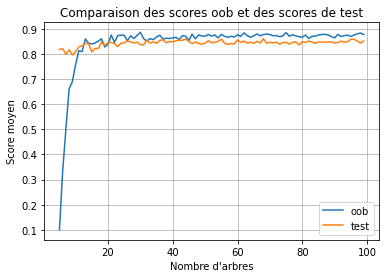

In [ ]:
plt.plot(tree_range, oob_error, label = 'oob')
plt.plot(tree_range, test_error, label = 'test')
title('Comparaison des scores oob et des scores de test')
plt.legend()
xlabel("Nombre d'arbres")
ylabel("Score moyen")
plt.grid(True)
plt.show()

Peu d'arbres implique une foret calculée avec vraiment peu d'arbres pour OOB et donc un score potentiellement plus faible que le score de la foret complète évaluée sur l'échantillon test.

Par ailleurs, lorsque la foret contient peu d'arbres, on note que certaines observations ne sont jamais dans les échantillons OOB (d'où les warnings).

Lorsque le nombre d'arbres est suffisamment grand, le score OOB finit par dépasser le score évalué via l'échantillon test. Ce phénomène peut s'expliquer par le fait que dans le cas OOB, nous utilisons toutes les données pour construire la forêt aléatoire, alors que dans le cas de l'évaluation sur l'échantillon test, les forêts aléatoires ne sont construites que sur les 4/5 ième des données, il est donc naturel que les performances soient supérieures dans le premier cas.

Pour ce qui concerne maintenant les performances de la méthode OOB, en tant que méthode d'estimation de l'erreur de généralisation, la littérature récente (voir par exemple les conclusions de [cette étude](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0201904)) indique que cette méthode tend à surestimer l'erreur de généralisation. Il s'agit d'un sujet de recherche encore ouvert.


> Plutôt que d'utiliser le score $R^2$, on peut choisir un autre score, par exemple estimer l'erreur quadratique de prédiction de la forêt, et là aussi de deux façons :
- en utilisant les échantillons OOB (avec le champ `.oob_prediction_` de la forêt ajustée) ;
- ou plus classiquement par validation croisée K-fold en utilisant la fonction `GridSearchCV`.
>
> Reprendre la comparaison précédente avec ce nouveau score. On pourra utiliser le scorer `neg_mean_squared_erro` de sklearn (voir la [doc](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules)). On peut de plus préciser le score souhaité dans la fonction `GridSearchCV` grâce à l'option `scoring` (voir [ici](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules)).

In [ ]:
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

# Scores oob (erreur quadratique)

oob_err = []
for ntree in tree_range:
    rf = RandomForestRegressor(n_estimators = ntree, oob_score = True)
    rf.fit(X_Bost, Y_Bost)
    oob_err.append(mean_squared_error(Y_Bost, rf.oob_prediction_))


# Scores de test avec (erreur quadratique)

my_kfold = KFold(n_splits = 5, shuffle = True, random_state=0)

tree_range = range(5,100)

tuned_parameters = {'n_estimators':tree_range}

RF=RandomForestRegressor(max_features=4)
Cart_grid = GridSearchCV(RF, tuned_parameters, cv = my_kfold, scoring = 'neg_mean_squared_error')

Cart_grid.fit(X_Bost,Y_Bost)
test_error = Cart_grid.cv_results_['mean_test_score']

C:\Users\kisan\anaconda3\lib\site-packages\sklearn\ensemble\_forest.py:833: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable oob estimates.
  warn("Some inputs do not have OOB scores. "
C:\Users\kisan\anaconda3\lib\site-packages\sklearn\ensemble\_forest.py:833: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable oob estimates.
  warn("Some inputs do not have OOB scores. "
C:\Users\kisan\anaconda3\lib\site-packages\sklearn\ensemble\_forest.py:833: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable oob estimates.
  warn("Some inputs do not have OOB scores. "
C:\Users\kisan\anaconda3\lib\site-packages\sklearn\ensemble\_forest.py:833: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable oob estimates.
  warn("Some inputs do not hav

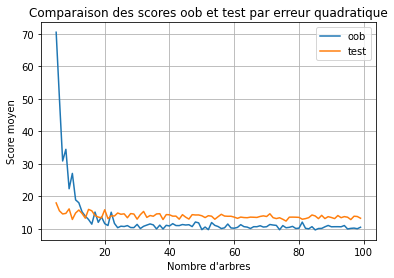

In [ ]:
plt.plot(tree_range, oob_err, label = 'oob')
plt.plot(tree_range, 1-test_error, label = 'test')
title('Comparaison des scores oob et test par erreur quadratique')
plt.legend()
xlabel("Nombre d'arbres")
ylabel("Score moyen")
plt.grid(True)
plt.show()

> On souhaite optimiser les performances du modèle de forêts aléaoires (basé sur 50 arbres). Pour cela :
> - découper l'échantillon initial en train - test (80% -  20%)
> - sur l'échantillon d'apprentissage, déterminer via une estimation des erreurs OOB :
        - le meilleur paramètre `max_leaf_nodes` (sur la grille `maxnode` proposée ci-dessous)
        - le meilleur paramètre `max_features` (autour de p/3 où p est le nombre de features initiales).
> - pour ces choix de paramètres, ajuster le modèle final sur l'échantillon d'apprentissage
> - évaluer la qualité prédictive sur l'échantillon test

Noter que la fonction `GridSearchCV`, qui par définition effectue des validations croisées, n'est pas adaptée pour cette recherche de paramètres par évaluation de l'erreur out of bag.

In [ ]:
# Découpage de l'échantillon initial en train-test

from sklearn.model_selection import train_test_split

X_Bost_train, X_Bost_test, Y_Bost_train, Y_Bost_test =train_test_split(X_Bost,Y_Bost,test_size=0.2, random_state=0)

In [ ]:
# Détermination des meilleurs paramètres

from sklearn.tree import DecisionTreeRegressor

maxnodes = [2,4,6,8,10,15,20,30,50,100,200,300,400,500,800]
maxfeatures=range(2,10)

oob_score_1=[]
for node in maxnodes:
    RF = RandomForestRegressor(n_estimators=50, max_leaf_nodes=node, oob_score =True)
    RF.fit(X_Bost_train, Y_Bost_train)
    oob_score_1.append(RF.oob_score_)


oob_score_2=[]
for feat  in maxfeatures:

    RF = RandomForestRegressor(n_estimators=50, max_features = feat, oob_score =True)
    RF.fit(X_Bost_train, Y_Bost_train)
    oob_score_2.append(RF.oob_score_)

maxnode =  maxnodes[oob_score_1.index(max(oob_score_1))]
maxfeature = maxfeatures[oob_score_2.index(max(oob_score_2))]

In [ ]:
print ('Le meilleur paramètre max_leaf_nodes est ', maxnode)
print ('Le meilleur paramètre max_features est ', maxfeature)

Le meilleur paramètre max_leaf_nodes est  200
Le meilleur paramètre max_features est  7


In [ ]:
RF = RandomForestRegressor(n_estimators=50, max_features = maxfeature, max_leaf_nodes = maxnode, oob_score =True)
RF.fit(X_Bost_train, Y_Bost_train)
print('Score de la RandomForest:',RF.score(X_Bost_test, Y_Bost_test))

Score de la RandomForest: 0.6795940844238038


> Faire de même pour des bagging trees et comparer les performances des deux modèles ainsi ajustés.

In [ ]:
from sklearn.ensemble import BaggingRegressor

maxnodes = [2,4,6,8,10,15,20,30,50,100,200,300,400,500,800]
maxfeatures=range(2,10)

oob_score1=[]
for node in maxnodes:
    tree = DecisionTreeRegressor(max_leaf_nodes=node)
    bagreg = BaggingRegressor(base_estimator=tree, n_estimators=50, oob_score = True)
    bagreg.fit(X_Bost_train, Y_Bost_train)
    oob_score1.append(bagreg.oob_score_)

oob_score2=[]
for feat in maxfeatures:
    tree = DecisionTreeRegressor(max_features=feat)
    bagreg = BaggingRegressor(base_estimator=tree, n_estimators=50, oob_score = True)
    bagreg.fit(X_Bost_train, Y_Bost_train)
    oob_score2.append(bagreg.oob_score_)

maxnode =  maxnodes[oob_score1.index(max(oob_score1))]
maxfeature = maxfeatures[oob_score2.index(max(oob_score2))]

In [ ]:
print ('Le meilleur paramètre max_leaf_nodes est ', maxnode)
print ('Le meilleur paramètre max_features est ', maxfeature)

Le meilleur paramètre max_leaf_nodes est  200
Le meilleur paramètre max_features est  5


In [ ]:
tree = DecisionTreeRegressor(max_leaf_nodes = maxnode, max_features = maxfeature)
bagtree = BaggingRegressor(base_estimator=tree, n_estimators=50)
bagtree.fit(X_Bost_train, Y_Bost_train)
print('Score du Bagging Regressor:',bagtree.score(X_Bost_test, Y_Bost_test))

Score du Bagging Regressor: 0.7159706928043977


# Importance des variables dans une forêt


##### Importance au sens de Gini

> Pour le modèle de forêt aléatoire sélectionné ci-dessus, afficher les [importances des variables au sens de Gini](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor.feature_importances_).

In [ ]:
# Importance des variables au sens de Gini

importance_gini = RF.feature_importances_
importance_gini

array([0.06600618, 0.01374251, 0.0614301 , 0.00285065, 0.05299693,
       0.30016435, 0.03016655, 0.04435309, 0.00609864, 0.0328375 ,
       0.06077994, 0.01559993, 0.31297362])

##### Importance par permutation OOB

Nous allons maintenant écrire une fonction pour calculer l'importance par permutation des variables en utilisant l'échantillon out of bag.
Il est possible de retrouver les indices de observations contenues dans l'échantillon bootstrap et dans l'échantillon out of bag associé à chaque arbre en utilisant les fonctions privées `_generate_sampled_indices` et `_generate_unsampled_indices` de la fonction `_forest` (dont le code source est disponible sur github [ici](https://github.com/scikit-learn/scikit-learn/blob/master/sklearn/ensemble/_forest.py)).
On commence par charger ces deux fonctions :

In [ ]:
from sklearn.ensemble._forest import _generate_unsampled_indices
from sklearn.ensemble._forest import _generate_sample_indices

Cette fonction prend en arguments :
- random_state : un entier qui encodre le tirage aléatoire de l'échantillon bootstrap (associé pour nous à un arbre)
- n_samples : nombre d'observations dans l'échantillon d'apprentissage
- n_samples_bootstrap : = nombre d'observations dans les échantillons bootstrap, égal à n_samples pour le cas qui nous intéresse ici.

Le `random_state` est un attribut disponible pour chaque arbre de la forêt. Par exemple pour le premier arbre :

In [ ]:
RF.estimators_[0].random_state

396302975

On peut ainsi retrouver pour le premier arbre la liste des indices des observations dans l'échantillon bootstrap et dans l'échantillon out of bag :

In [ ]:
boot_indices = _generate_sample_indices(RF.estimators_[0].random_state,shape(X_Bost)[0],shape(X_Bost)[0])
boot_indices

array([ 53, 345, 385, 449, 458, 318, 263,  51,  79, 255, 157, 193, 178,
       298, 372,  41,  12,  40, 186, 263, 482,  99,  85, 325, 239, 370,
       368, 152, 264, 138, 418, 311, 346,  99, 465, 253,  94, 291,  99,
       256, 395, 491, 449, 166, 144, 122, 318, 233,  86, 492, 216, 388,
       186,  83, 505, 158, 395,  57, 262, 358, 371, 211, 492, 340, 319,
       166, 229, 281, 122, 238,  39, 455,  98, 240,  55, 468, 307, 391,
       299, 187,  82, 168, 218, 179, 113,  52,   8,  61, 109, 300, 301,
        97, 500, 393,  72, 213, 286, 190, 272, 275,  73, 151, 103, 252,
       371, 205, 465, 208, 311, 398, 254, 193,  44,  61,  91, 448, 402,
       303, 372, 335, 126, 227, 213, 104, 305, 110,  63, 395, 171, 393,
       347, 446, 181, 370, 184, 110, 301, 155, 271, 332, 269,  77, 393,
       341, 270,  16,  93,  87,  19, 392, 216, 243, 139, 204, 452, 192,
        60, 194,  90, 265, 420,   1,  46, 145, 298, 325, 286, 330, 351,
       271, 228, 376, 254, 391, 491, 106,  39,  89, 229, 494,  2

In [ ]:
oob_indices = _generate_unsampled_indices(RF.estimators_[0].random_state,shape(X_Bost)[0],shape(X_Bost)[0])
oob_indices

array([  2,   3,   4,   5,   6,   7,   9,  11,  13,  14,  15,  18,  21,
        23,  24,  25,  29,  31,  32,  33,  34,  35,  36,  38,  43,  45,
        47,  58,  59,  64,  68,  71,  74,  75,  76,  80,  81,  84,  92,
        96, 100, 102, 108, 116, 117, 118, 120, 121, 123, 129, 131, 132,
       133, 134, 136, 142, 149, 150, 161, 162, 165, 170, 173, 176, 177,
       182, 183, 188, 189, 195, 196, 198, 199, 201, 202, 206, 207, 219,
       220, 225, 231, 232, 235, 237, 245, 251, 259, 266, 267, 268, 273,
       276, 277, 279, 280, 282, 283, 285, 287, 289, 290, 292, 294, 295,
       296, 302, 304, 306, 308, 309, 310, 314, 322, 323, 324, 326, 327,
       331, 336, 337, 342, 348, 349, 350, 353, 354, 355, 356, 357, 359,
       362, 363, 365, 367, 369, 373, 374, 375, 377, 378, 379, 381, 383,
       384, 390, 396, 399, 400, 401, 403, 405, 407, 408, 409, 412, 413,
       415, 417, 424, 425, 426, 431, 434, 436, 437, 438, 441, 447, 453,
       454, 456, 460, 461, 463, 466, 470, 472, 474, 475, 476, 47

> vérifier que tous les indices sont bien présents dans l'un ou l'autre des deux échantillons

In [ ]:
# Vérification que tous les indices sont soit dans boot_indices soit dans oob_indices

n = shape(X_Bost)[0]
res = [1 for k in range(n)] # Liste indiquant si l'indice i est dans l'un au moins des deux échantillons (Oui=0 & Non=1)

for elt in boot_indices:
    res[elt]=0 # Si l'indice elt est dans boot_indices alors on met res[elt] à 0

for elt in oob_indices:
    res[elt]=0 # Si l'indice elt est dans oob_indices alors on met res[elt] à 0

if sum(res)==0: # sum(res) est le nombre d'indices étant ni dans l'un ni dans l'autre échantillon
    print("Tous les indices sont dans l'un ou l'autre des deux échantillons")
else:
    print("Certains indices ne sont ni dans l'un ni dans l'autre")

Tous les indices sont dans l'un ou l'autre des deux échantillons


> Ecrire maintenant une fonction `importance_permutation_oob` qui prend en arguments une forêt aléatoire et les données d'apprentissage X,y (surlesquelles la forêt a été ajustée) et qui renvoie les importances par permutation calculées sur les échantillons OOB.

In [ ]:
# Fonction importance_permutation_oob

def importance_permutation_oob(forest, X, y):
    boot_indices = _generate_sample_indices(forest.random_state,shape(X)[0],shape(X)[0])
    X_oob = []
    Y_oob = []
    for elt in boot_indices:
        X_oob.append(X[elt])
        Y_oob.append(y[elt])
    forest.fit(X_oob, Y_oob)
    mean_importance = forest.feature_importances_
    return mean_importance

> Appliquer cette fonction sur les données Boston.

In [ ]:
# Application de cette fonction sur les données Boston

importance_oob = importance_permutation_oob(RandomForestRegressor(max_leaf_nodes=maxnode, max_features=maxfeature).fit(X_Bost_train, Y_Bost_train), X_Bost_train, Y_Bost_train)
importance_oob

array([0.07127094, 0.00624159, 0.04359764, 0.00307045, 0.02627949,
       0.31571116, 0.02768293, 0.03997948, 0.00724322, 0.03965614,
       0.101897  , 0.01441212, 0.30295784])

##### Importance par permutation sur échantillon de test

> La fonction [`permutation_importance`](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html#sklearn.inspection.permutation_importance)
 permet de calculer l'importance, mais en permutant cette fois les variables d'un autre échantillon c'est à dire typiquement un échantillon test. Appliquer cette fonction sur la forêt aléatoire ajustée sur les données Boston

In [ ]:
from sklearn.inspection import permutation_importance

importance_test = permutation_importance(RandomForestRegressor(max_leaf_nodes=maxnode, max_features=maxfeature).fit(X_Bost_train, Y_Bost_train), X_Bost_test, Y_Bost_test).importances_mean
importance_test

array([ 0.01716472,  0.0004965 ,  0.00377988,  0.00678143,  0.02321225,
        0.32604818,  0.01348533,  0.0579065 , -0.00134434,  0.00960846,
        0.01928793,  0.01500595,  0.35319159])

>  Représenter sur un même graphique en bâtons les 3 types d'importance, en les renormalisant pour chacune d'elle prenne la valeur 100 sur la variable d'importance maximale.

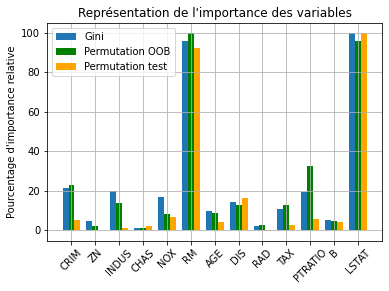

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pylab

width = 1

def to_relative(L):
    res = []
    M = max(L)
    for elt in L:
        res.append(100*elt/M) # Pour avoir des pourcentages
    return res

plt.bar([1/2 + 4*i for i in range(13)], to_relative(importance_gini), width, label='Gini')
plt.bar([3/2 + 4*i for i in range(13)], to_relative(importance_oob), width, label='Permutation OOB', color='green')
plt.bar([5/2 + 4*i for i in range(13)], to_relative(importance_test), width, label='Permutation test', color='orange')

pylab.xticks([1.5 + 4*i for i in range(13)], ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"], rotation=45)

plt.ylabel("Pourcentage d'importance relative")
plt.title("Représentation de l'importance des variables")
plt.grid()
plt.legend()
plt.show()


Sur cet exemple, les trois classements de variables (obtenus en classant les variables par importance décroissante) sont comparables.

# Classifieur par forêt aléatoire

> Ajuster un classifieur par forêt aléatoire (contenant 100 arbres) sur le jeu de données SPAM en sélectionnant le paramètre `max_features` via l'erreur OOB.

In [ ]:
import pandas as pd
import numpy as np
# URL of the spambase.names file
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.names"
# Read the file directly from the URL
features_names = pd.read_csv(url, delim_whitespace=True, header=None, skiprows=33)
data_path = url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"
Spam_data =pd.read_csv(data_path, header=None)
X_Spam = Spam_data.values[:,0:57]
Y_Spam = Spam_data.values[:,57]

<ipython-input-4-903724eaa2f1>:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  features_names = pd.read_csv(url, delim_whitespace=True, header=None, skiprows=33)


In [ ]:
file_path=  "C:/Users/kisan/Downloads/Apprentissage stat/spambase/"
data_path = file_path + "spambase.names"
features_names = pd.read_csv(data_path,delim_whitespace=True,header=None)
data_path = file_path + "spambase.data"
Spam_data = pd.read_csv(data_path,delim_whitespace=False,header=None)
X_Spam = Spam_data.values[:,0:57]
Y_Spam = Spam_data.values[:,57]

In [ ]:
maxfeatures = range(2,57)

oob_scores3 = []

for max_feats in maxfeatures:
    RF = RandomForestRegressor(n_estimators=100, max_features=max_feats, oob_score=True)
    RF.fit(X_Spam,Y_Spam)
    oob_scores3.append(RF.oob_score_)

def indice_du_max(L):
    res = 0
    M = L[0]
    n = len(L)
    for k in range(n):
        if L[k] > M:
            M = L[k]
            res = k
    return res

i_max3 = indice_du_max(oob_scores3)

maxfeatures3 = maxfeatures[i_max3]

print("Le meilleur max_features est :", maxfeatures3)

Le meilleur max_features est : 8


In [ ]:
RF = RandomForestRegressor(n_estimators=100, max_features=maxfeatures3, oob_score=True)
RF.fit(X_Spam,Y_Spam)

RandomForestRegressor(max_features=8, oob_score=True)

>Représenter l'importance de Gini pour le modèle sélectionné (uniquement pour les 20 principales).

In [ ]:
importance_gini = RF.feature_importances_


def indice_insertion(x,L):
    '''Renvoie l'indice auquel insérer x dans L supposée triée dans l'ordre croissant'''
    n = len(L)
    i = 0
    while i<n and x>L[i]:
        i+=1
    # Si x est plus petit que tout elt de L alors on renvoit -1
    return i-1

def decalage(i,L):
    '''Décale d'un rang vers la gauche tout elt de L d'indice inf ou égal à i'''
    for k in range(1,i+1):
        L[k-1] = L[k]
    # On ne renvoie rien car on modifie L sur place

def insertion(x,L):
    ''' L est supposée déjà triéée dans l'ordre croissant'''
    i = indice_insertion(x,L)
    if i>=0:
        decalage(i,L) # On fait une place pour x
        L[i] = x # On n'oublie pas d'insérer x dans L
    # On ne renvoie rien car on modifie L sur place

les_importances_max = [0 for k in range(21)]
les_indices_des_importances_max = [-1 for k in range(20)] # Initialisation à -1 pour détecter d'eventuelles erreurs

n = len(importance_gini)
for k in range(n):
    # Mise à jour de la liste les_importances_max
    insertion(importance_gini[k], les_importances_max)
    # Mise à jour de la liste les_indices_des_importances_max
    i = indice_insertion(importance_gini[k], les_importances_max)
    if i>=0:
        decalage(i, les_indices_des_importances_max)
        les_indices_des_importances_max[i] = k

les_importances_max = les_importances_max[1:] # Bidouillage pour retrouver les 20 plus grandes valeurs

In [ ]:
# Récupération des noms des features les plus importantes

les_features_names = [] # Liste des features_names
for k in range(57):
    x = features_names.values[k][0]
    n = len(x)
    new_x = x[:(n-1)] # Pour retirer les ":" à la fin de chaque feature
    les_features_names.append(new_x)

les_features_importantes = []
for elt in les_indices_des_importances_max:
    les_features_importantes.append(les_features_names[elt])

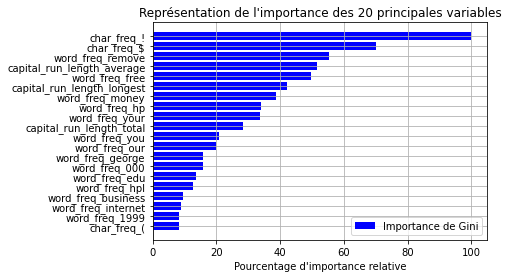

In [ ]:
import matplotlib.pyplot as plt
import pylab
width = 1.5

plt.barh([2*i for i in range(20)], to_relative(les_importances_max), width, label='Importance de Gini', color='blue')

pylab.yticks([2*i for i in range(20)], les_features_importantes)

plt.xlabel("Pourcentage d'importance relative")
plt.title("Représentation de l'importance des 20 principales variables")
plt.grid()
plt.legend()
plt.show()

# Recursive Feature Elimination (RFE)

Lorsque le prédicteur est construit sur un grand nombre de variables, ce dernier peut être sujet à un effet de sur-apprentissage. Pour améliorer les performances du modèle, on essaye alors de réduire le nombre de variables utilisées.

La méthode RFE (recursive feature elimination) est une méthode de sélection de variables de type "backward" : partant du plus grand modèle, on retire progressivement les variables les moins "intéressantes" du modèle jusqu'à obtenir une erreur de test minimale.

Noter que cette stratégie se distingue de celle qui consiste à réduire la dimension en amont de l'apprentissage supervisé, en effectuant par exemple une analyse en composantes principales sur les données brutes. Dans ce dernier cas, on crée en effet de nouvelles variables pour tenter de synthétiser l'information disponible.


> Pour le jeu de données SPAM, implémenter la méthode RFE pour la forêt aléatoire en considérant comme critère de sélection l'importance de type GINI ( `.feature_importances_`).
>
>    - Initialisation :  ajuster une forêt aléatoire sur le jeu de données complet  (avec toutes les variables)
>    - Tant qu'il reste des variables :
>        - Calculer les importances sur la forêt courante
>        - Retirer la (les) variable(s) la (les) moins importante(s)
>        - Ajuster sur les données une forêt aléatoire en utilisant les variables restantes
>        - Calculer l'erreur de test de cette forêt
>    - A partir des erreurs de test évaluées sur la suite (emboitée) des modèles parcourus, indiquer le groupe de variables finalement sélectionné.
>


In [ ]:
## Initialisation

RF = RandomForestRegressor(n_estimators=100, oob_score=True)
RF.fit(X_Spam,Y_Spam)

RandomForestRegressor(oob_score=True)

In [ ]:
## Algorithme auxiliaire

# Détermination de la variable la moins importante
def indice_du_min(L):
    n = len(L)
    m = L[0]
    ind = 0
    for k in range(1,n):
        if L[k]<m:
            m = L[k]
            ind = k
    return ind

In [ ]:
## Initialisation des variables

file_path = "C:/Users/kisan/Downloads/Apprentissage stat/spambase/"
data_path = file_path + "spambase.names"
features_names = pd.read_csv(data_path,delim_whitespace=True,header=None)

featuresnames = [] # Liste des features_names
for k in range(57):
    x = features_names.values[k][0]
    n = len(x)
    new_x = x[:(n-1)] # Pour retirer les ":" à la fin de chaque feature
    featuresnames.append(new_x)

X = X_Spam # Pour ne pas modifier X_Spam

# Les indices sur les listes suivantes correspodent au nombre de variables supprimées
les_erreurs = [] # On va mettre les erreurs en allant
les_groupes_de_variables = [] # Les groupes de variables retenues (c'est une matrice)

les_erreurs.append(RF.oob_score_)
les_groupes_de_variables.append(featuresnames)

## Boucle
for nb_variables_supprimees in range(57-maxfeatures3):

    # Calcul des importances sur la forêt courante
    importances = RF.feature_importances_
    ind = indice_du_min(importances) # Calcul de l'indice du minimum

    # Suppression de la variable la moins importante
    del featuresnames[ind]
    n = len(X)
    m = len(X[0])
    X_temp = [[] for k in range(n)]
    for i in range(n):
        for j in range(m):
            if j != ind:
                X_temp[i].append(X[i][j])
    X = np.array(X_temp)

    # Ajustement sur les données avec les variables restantes
    RF.fit(X, Y_Spam)

    # Calcul de l'erreur pour cette forêt
    les_erreurs.append(RF.oob_score_)
    les_groupes_de_variables.append(featuresnames)

In [ ]:
i_max = indice_du_max(les_erreurs)

print("Le groupe de variable finalement séléctionnées est :", les_groupes_de_variables[i_max])

Le groupe de variable finalement séléctionnées est : ['word_freq_remove', 'word_freq_free', 'word_freq_hp', 'char_freq_!', 'char_freq_$', 'capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total']


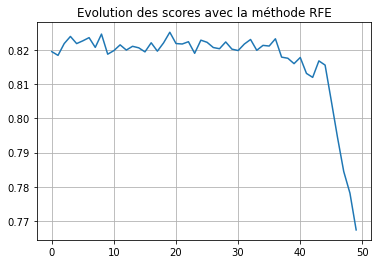

In [ ]:
oob_score_vec = les_erreurs
plot(oob_score_vec)
plt.grid()
title('Evolution des scores avec la méthode RFE')
plt.show()

Sur cet exemple, on voit cependant que la méthode RFE ne permet malheureusement pas d'améliorer les performances.